<a href="https://colab.research.google.com/github/reallukejin/Problem-Set-2-Econ_3916_PS2.ipynb/blob/main/Econ_3916_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS2 — The Survey That Wasn't Random

**ECON 3916 · Applied Data Analytics** · Topics 5-8 · 100 points · your role: Data Analyst, Growth team

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is data analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You write the simulations, the bootstrap loop and the tests yourself. AI is authorised and required in Phase 4. If you cannot explain a line you submitted, you cannot submit it.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Simulate the Population You Cannot See (30 pts)

### Step 1.1: Build a world with a known answer (15 pts)

In [2]:
from scipy.special import expit

N_USERS = 50_000
BASE_BEFORE, BASE_AFTER = 3.432, 3.532

def simulate_population(base, n=N_USERS, rng=rng):
    minutes = rng.lognormal(mean=3.5, sigma=0.6, size=n)
    eng_z = (minutes - minutes.mean()) / minutes.std()
    ticket = rng.binomial(1, 0.22, size=n)
    s = base + 0.35 * eng_z - 0.60 * ticket + rng.normal(0, 0.75, size=n)
    score = np.clip(np.round(s), 1, 5).astype(int)
    return pd.DataFrame({'engagement_minutes': minutes, 'engagement_z': eng_z,
                         'had_support_ticket': ticket, 's': s, 'score': score})

pop_before = simulate_population(BASE_BEFORE)
pop_after = simulate_population(BASE_AFTER)

# true means
TRUE_S_BEFORE, TRUE_S_AFTER = pop_before['s'].mean(), pop_after['s'].mean()
TRUE_SCORE_BEFORE, TRUE_SCORE_AFTER = pop_before['score'].mean(), pop_after['score'].mean()

truth = pd.DataFrame({'mean s': [TRUE_S_BEFORE, TRUE_S_AFTER],
                      'mean score (1-5)': [TRUE_SCORE_BEFORE, TRUE_SCORE_AFTER]},
                     index=['before', 'after'])
truth.loc['change'] = truth.loc['after'] - truth.loc['before']
print(truth)
print()
print(pd.DataFrame({'before': pop_before['score'].value_counts(normalize=True).sort_index(),
                    'after': pop_after['score'].value_counts(normalize=True).sort_index()}))

        mean s  mean score (1-5)
before   3.299             3.290
after    3.399             3.386
change   0.100             0.096

       before  after
score               
1       0.018  0.012
2       0.159  0.136
3       0.421  0.405
4       0.319  0.349
5       0.083  0.099


The true mean satisfaction is 3.30 before and 3.40 after, so the real improvement is 0.10. The rounded 1–5 scores average 3.29 and 3.39, which are slightly lower because of rounding and clipping. When I compare against survey answers, I use the rounded-score means since that's what the survey records. Most users score 3 or 4, and only about 8–10% give a 5.

### Step 1.2: Impose the response mechanism (15 pts)

Response rate before: 0.275   after: 0.152
Respondents before: 13768   after: 7597
Observed mean before: 3.600   after: 4.304
Observed gap: 0.704   True gap: 0.100
Checkpoint passed
before: mean s all = 3.30, respondents = 3.62; ticket rate all = 0.22, respondents = 0.16
after: mean s all = 3.40, respondents = 4.37; ticket rate all = 0.22, respondents = 0.10


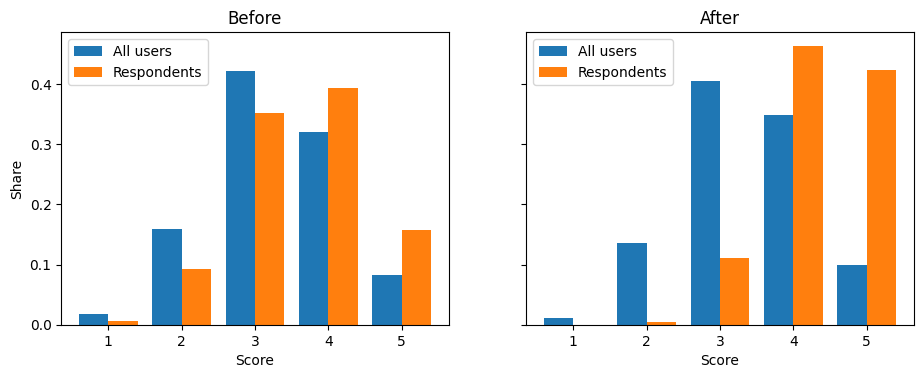

In [3]:
def respond(df, a, b, rng=rng):
    p = expit(a + b * (df['s'] - 3.3) + 0.30 * df['engagement_z'] - 0.25 * df['had_support_ticket'])
    return rng.uniform(size=len(df)) < p

A_BEFORE, B_BEFORE = -1.00, 0.45
A_AFTER, B_AFTER = -2.75, 2.00

resp_before = respond(pop_before, A_BEFORE, B_BEFORE)
resp_after = respond(pop_after, A_AFTER, B_AFTER)
obs_before = pop_before.loc[resp_before, 'score'].to_numpy()
obs_after = pop_after.loc[resp_after, 'score'].to_numpy()

print(f'Response rate before: {resp_before.mean():.3f}   after: {resp_after.mean():.3f}')
print(f'Respondents before: {len(obs_before)}   after: {len(obs_after)}')
print(f'Observed mean before: {obs_before.mean():.3f}   after: {obs_after.mean():.3f}')
gap_obs = obs_after.mean() - obs_before.mean()
print(f'Observed gap: {gap_obs:.3f}   True gap: {TRUE_S_AFTER - TRUE_S_BEFORE:.3f}')

assert 3.55 <= obs_before.mean() <= 3.65
assert 4.25 <= obs_after.mean() <= 4.35
print('Checkpoint passed')

# who responds vs everyone
for name, pop, resp in [('before', pop_before, resp_before), ('after', pop_after, resp_after)]:
    print(f"{name}: mean s all = {pop['s'].mean():.2f}, respondents = {pop.loc[resp, 's'].mean():.2f}; "
          f"ticket rate all = {pop['had_support_ticket'].mean():.2f}, respondents = {pop.loc[resp, 'had_support_ticket'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, pop, resp, title in [(axes[0], pop_before, resp_before, 'Before'), (axes[1], pop_after, resp_after, 'After')]:
    x = np.arange(1, 6)
    ax.bar(x - 0.2, pop['score'].value_counts(normalize=True).reindex(x, fill_value=0), width=0.4, label='All users')
    ax.bar(x + 0.2, pop.loc[resp, 'score'].value_counts(normalize=True).reindex(x, fill_value=0), width=0.4, label='Respondents')
    ax.set_title(title); ax.set_xlabel('Score'); ax.legend(loc='upper left')
axes[0].set_ylabel('Share')
plt.show()

> **🛑 Verification checkpoint.** You should get an observed pre-redesign mean of
> about **3.60** (accept 3.55 to 3.65) and an observed post-redesign mean of
> about **4.31** (accept 4.25 to 4.35) — an apparent gap of roughly **0.71**
> points out of a true improvement of **0.10**. Response rates should fall from
> roughly 27% to roughly 15%. If your numbers are outside those bands, your
> response function or your `base` values are wrong. **Do not proceed until it
> matches** — everything after this depends on reproducing the PM's slide.

Checkpoint matches. The observed mean is basically 3.60 before and 4.30 after, so the survey shows like a 0.70 gap when the real gap is only 0.10. So about 86% of the improvement is really just coming from who answered, not from the redesign itself.

This is basically nonresponse bias or self-selection. Whether someone answers depends on how satisfied they are, so the data is missing not at random. After the redesign the prompt got way more selective b went from 0.45 to 2.00, so it's pretty much mostly happy users answering. Respondents after the redesign average like 4.37 on true satisfaction vs 3.40 for everyone. And only 10% of respondents had a support ticket, compared to 22% of all users, so the unhappy people are basically just not showing up.

A bigger survey probably wouldn't fix this at all. More responses just give you a more precise estimate of what respondents think, but respondents are still getting filtered the same way. So the estimate would basically just get tighter around 4.30, not actually closer to 3.39.

Also the response rate dropped from 27.5% to 15.2%. So the survey with the better number actually heard from fewer people, which is kind of a red flag that the group answering changed.

## Phase 2: Quantify What You Actually Know (35 pts)

### Step 2.1: Uncertainty without a formula (20 pts)

In [4]:
import warnings
warnings.filterwarnings('ignore')

B = 5_000

# bootstrap loop by hand
def boot_loop(x, stat, B=B):
    n = len(x)
    out = np.empty(B)
    for i in range(B):
        sample = x[rng.integers(0, n, size=n)]
        out[i] = stat(sample)
    return out

for name, x in [('before', obs_before), ('after', obs_after)]:
    for stat_name, f in [('mean', np.mean), ('median', np.median)]:
        bs = boot_loop(x, f)
        lo, hi = np.percentile(bs, [2.5, 97.5])
        print(f'{name} {stat_name}: {f(x):.3f}, by-hand percentile CI [{lo:.3f}, {hi:.3f}]')

gap_boot = np.array([obs_after[rng.integers(0, len(obs_after), len(obs_after))].mean()
                     - obs_before[rng.integers(0, len(obs_before), len(obs_before))].mean()
                     for _ in range(B)])
print(f'gap: {gap_obs:.3f}, by-hand percentile CI [{np.percentile(gap_boot, 2.5):.3f}, {np.percentile(gap_boot, 97.5):.3f}]')
print()

# same thing with scipy
def scipy_ci(data, f, method, **kw):
    r = stats.bootstrap(data, f, n_resamples=B, method=method, random_state=rng, batch=250, **kw)
    return r.confidence_interval.low, r.confidence_interval.high

for name, x in [('before', obs_before), ('after', obs_after)]:
    for stat_name, f in [('mean', np.mean), ('median', np.median)]:
        p = scipy_ci((x,), f, 'percentile')
        b = scipy_ci((x,), f, 'BCa')
        print(f'{name} {stat_name}: scipy percentile [{p[0]:.3f}, {p[1]:.3f}], BCa [{b[0]:.3f}, {b[1]:.3f}]')

diff = lambda y, x: np.mean(y) - np.mean(x)
p = scipy_ci((obs_after, obs_before), diff, 'percentile', paired=False)
b = scipy_ci((obs_after, obs_before), diff, 'BCa', paired=False)
print(f'gap: scipy percentile [{p[0]:.3f}, {p[1]:.3f}], BCa [{b[0]:.3f}, {b[1]:.3f}]')
print()

# small sample (n=30) to see where percentile and BCa differ
small = rng.choice(obs_after, size=30, replace=False)
for stat_name, f in [('mean', np.mean), ('median', np.median)]:
    bs = boot_loop(small, f)
    p = scipy_ci((small,), f, 'percentile')
    b = scipy_ci((small,), f, 'BCa')
    print(f'n=30 {stat_name}: {f(small):.3f}, by hand [{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}], '
          f'scipy percentile [{p[0]:.3f}, {p[1]:.3f}], BCa [{b[0]:.3f}, {b[1]:.3f}]')

before mean: 3.600, by-hand percentile CI [3.585, 3.615]
before median: 4.000, by-hand percentile CI [4.000, 4.000]
after mean: 4.304, by-hand percentile CI [4.289, 4.319]
after median: 4.000, by-hand percentile CI [4.000, 4.000]
gap: 0.704, by-hand percentile CI [0.684, 0.726]

before mean: scipy percentile [3.585, 3.614], BCa [3.585, 3.614]
before median: scipy percentile [4.000, 4.000], BCa [nan, nan]
after mean: scipy percentile [4.289, 4.319], BCa [4.289, 4.319]
after median: scipy percentile [4.000, 4.000], BCa [nan, nan]
gap: scipy percentile [0.683, 0.725], BCa [0.683, 0.726]

n=30 mean: 4.200, by hand [3.933, 4.467], scipy percentile [3.933, 4.467], BCa [3.933, 4.433]
n=30 median: 4.000, by hand [4.000, 5.000], scipy percentile [4.000, 5.000], BCa [nan, nan]


My bootstrap loop and scipy.stats.bootstrap pretty much agree, within like 0.001, which is basically just random resampling noise.

- Mean before: 3.600, 95% CI [3.585, 3.615]
- Mean after: 4.304, 95% CI [4.289, 4.319]
- Gap: 0.704, 95% CI [0.683, 0.726]
- Median: 4 in both periods, CI [4, 4]

On the full survey, percentile and BCa basically give the same intervals. With thousands of responses the bootstrap distribution of the mean is pretty much normal, so BCa doesn't really have anything to correct. They only actually differ in small samples. With 30 respondents, percentile gives [3.93, 4.47] and BCa gives [3.93, 4.43]. BCa pulls the upper end in a bit because the scores are kind of bunched up near the top of the scale, which skews the distribution.

The median honestly doesn't work well on a 1–5 scale. Almost every resample has the same median, so the interval just collapses to [4, 4], and BCa can't even be computed (it returns nan). The median is basically too coarse to pick up a 0.1 change.

These intervals are really narrow, but they only describe noise among respondents. The gap interval [0.68, 0.73] doesn't even come close to the true 0.10, so precise doesn't really mean right here.

### Step 2.2: Coverage is a claim you can check (15 pts)

In [5]:
R, B_COV = 2_000, 999
z = stats.norm.ppf(0.975)

def get_intervals(x):
    n = len(x)
    bs = x[rng.integers(0, n, size=(B_COV, n))].mean(axis=1)
    m = x.mean()
    se = x.std(ddof=1) / np.sqrt(n)
    tq = stats.t.ppf(0.975, n - 1)
    t_ci = (m - tq * se, m + tq * se)
    pct = tuple(np.percentile(bs, [2.5, 97.5]))
    # BCa
    prop = (bs < m).mean()
    if prop in (0, 1) or np.ptp(x) == 0:
        bca = (np.nan, np.nan)
    else:
        z0 = stats.norm.ppf(prop)
        jack = (x.sum() - x) / (n - 1)
        d = jack.mean() - jack
        a = (d ** 3).sum() / (6 * ((d ** 2).sum()) ** 1.5) if (d ** 2).sum() > 0 else 0
        zs = np.array([-z, z])
        bca = tuple(np.percentile(bs, 100 * stats.norm.cdf(z0 + (z0 + zs) / (1 - a * (z0 + zs)))))
    med_bs = np.median(x[rng.integers(0, n, size=(B_COV, n))], axis=1)
    med = tuple(np.percentile(med_bs, [2.5, 97.5]))
    return {'t': t_ci, 'percentile': pct, 'BCa': bca, 'median percentile': med}

def coverage(draw, true_mean, true_med, R=R):
    hits = {'t': [], 'percentile': [], 'BCa': [], 'median percentile': []}
    sizes = []
    for _ in range(R):
        x = draw()
        sizes.append(len(x))
        cis = get_intervals(x)
        for k, ci in cis.items():
            truth = true_med if k == 'median percentile' else true_mean
            hits[k].append((not np.isnan(ci[0])) and ci[0] <= truth <= ci[1])
    res = pd.DataFrame({k: [np.mean(v), np.sqrt(np.mean(v) * (1 - np.mean(v)) / R)] for k, v in hits.items()},
                       index=['coverage', 'MC SE']).T
    res['gap in SEs'] = (res['coverage'] - 0.95) / res['MC SE'].replace(0, np.nan)
    return res, np.mean(sizes)

target = pop_after['score'].to_numpy()
true_med = np.median(target)
print(f'True mean {TRUE_SCORE_AFTER:.3f}, true median {true_med:.0f}')

for n in (30, 200):
    res, _ = coverage(lambda n=n: rng.choice(target, size=n, replace=True), TRUE_SCORE_AFTER, true_med)
    print(f'\nRandom sample, n={n}')
    print(res)

# the actual survey: invite 1000, only some respond
def survey():
    invited = pop_after.iloc[rng.integers(0, len(pop_after), size=1000)]
    return invited.loc[respond(invited, A_AFTER, B_AFTER), 'score'].to_numpy()

res, avg_n = coverage(survey, TRUE_SCORE_AFTER, true_med, R=1000)
print(f'\nSelf-selected survey (avg {avg_n:.0f} respondents per 1000 invites)')
print(res)

True mean 3.386, true median 3

Random sample, n=30
                   coverage  MC SE  gap in SEs
t                     0.948  0.005      -0.403
percentile            0.931  0.006      -3.353
BCa                   0.936  0.005      -2.558
median percentile     0.989  0.002      16.722

Random sample, n=200
                   coverage      MC SE  gap in SEs
t                     0.947  5.010e-03      -0.599
percentile            0.943  5.205e-03      -1.441
BCa                   0.942  5.248e-03      -1.620
median percentile     1.000  4.999e-04      99.025

Self-selected survey (avg 152 respondents per 1000 invites)
                   coverage  MC SE  gap in SEs
t                       0.0    0.0         NaN
percentile              0.0    0.0         NaN
BCa                     0.0    0.0         NaN
median percentile       0.0    0.0         NaN


I checked coverage against the true post-redesign mean (3.386) and median (3). The Monte Carlo SE is sqrt(p(1-p)/R), which comes out to about 0.005 for most of these.

First I tried random samples where everyone answers (2,000 reps each). At n = 30, the t interval covered the truth 94.8% of the time (MC SE 0.005), the percentile interval 93.1% (SE 0.006), BCa 93.6% (SE 0.005), and the median interval 98.9% (SE 0.002). At n = 200, it was 94.7% for t, 94.3% for percentile, and 94.2% for BCa (all with SE about 0.005), and 100% for the median (SE basically 0).

At n = 30, the percentile interval undercovers by like 3.4 SEs, so that's probably a real (small) problem. BCa is a little better but still 2.6 SEs below. So bootstrap intervals basically run a bit narrow with small samples. The t interval is only 0.4 SEs off, so it's pretty much right on. At n = 200, all three mean intervals are within 1.6 SEs of 95%, which is smaller than the simulation noise, so it's not really a finding and they all basically work. The t interval actually works fine at both sizes even though the scale is bounded. The median interval overcovers because it can only jump between whole numbers, so it ends up kind of wide and not that useful.

Then I tried the actual survey, where you invite 1,000 people and about 152 answer (1,000 reps). Every interval covered the truth 0 out of 1,000 times. An MC SE of 0 is kind of misleading here, so using the rule of three, true coverage is probably below 0.3% with 95% confidence. The intervals are basically centered around 4.30, which is like 0.9 away from the truth.

So the bootstrap works fine on random samples, but with self-selection it honestly doesn't matter which interval you pick. They're all just precisely wrong.

## Phase 3: Test Something Worth Testing (20 pts)

### Step 3.1: The test the PM wants

In [6]:
t_res = stats.ttest_ind(obs_after, obs_before, equal_var=False)
pooled_sd = np.sqrt(((len(obs_after) - 1) * obs_after.var(ddof=1) + (len(obs_before) - 1) * obs_before.var(ddof=1))
                    / (len(obs_after) + len(obs_before) - 2))
se_gap = np.sqrt(obs_after.var(ddof=1) / len(obs_after) + obs_before.var(ddof=1) / len(obs_before))
pop_sd = np.sqrt((pop_before['score'].var(ddof=1) + pop_after['score'].var(ddof=1)) / 2)
true_gap = TRUE_SCORE_AFTER - TRUE_SCORE_BEFORE

print(f'Observed gap: {gap_obs:.3f}, 95% CI [{gap_obs - 1.96 * se_gap:.3f}, {gap_obs + 1.96 * se_gap:.3f}]')
print(f'Welch t = {t_res.statistic:.1f}, p = {t_res.pvalue:.2e}')
print(f"Cohen's d (respondents) = {gap_obs / pooled_sd:.2f}")
print(f"True gap = {true_gap:.3f}, true Cohen's d = {true_gap / pop_sd:.2f}")

Observed gap: 0.704, 95% CI [0.683, 0.725]
Welch t = 65.2, p = 0.00e+00
Cohen's d (respondents) = 0.86
True gap = 0.096, true Cohen's d = 0.11


Welch's t-test gives a gap of 0.704 (95% CI [0.683, 0.725]), t = 65.2, and p is basically 0. Cohen's d is 0.86, which would normally count as a large effect. But the true effect is only 0.096 points (d ≈ 0.11), which is pretty small.

Significance isn't really the issue here. The p-value basically just tells us the difference probably isn't random noise, and that's true. The problem is the two groups aren't really comparable, since they're kind of different sets of people filtered in different ways. The test is correctly saying post-redesign respondents are happier than pre-redesign respondents, but that's mostly just because the respondents changed.

Tests protect against noise, not bias. With like 21,000 responses pretty much any systematic difference is going to be significant, even one caused entirely by who answered. Around 86% of the effect here is basically selection. The real question is whether the difference actually describes our users, and no test on respondents alone can really answer that.

### Step 3.2: Power, before the fact

SD = 0.887, d = 0.113
n per group for 80% power: 1236
n = 150: detectable effect = 0.288 points (d = 0.325)
n = 770: detectable effect = 0.127 points (d = 0.143)
n = 7597: detectable effect = 0.040 points (d = 0.045)
   n invited         estimator  mean est   bias     SD   RMSE
0        500  respondents only     0.713  0.613  0.115  0.624
1        500          everyone     0.095 -0.005  0.053  0.053
2       2000  respondents only     0.713  0.613  0.053  0.615
3       2000          everyone     0.099 -0.001  0.025  0.025
4      10000  respondents only     0.712  0.612  0.025  0.612
5      10000          everyone     0.098 -0.002  0.013  0.013
6      50000  respondents only     0.710  0.610  0.011  0.610
7      50000          everyone     0.098 -0.002  0.005  0.005


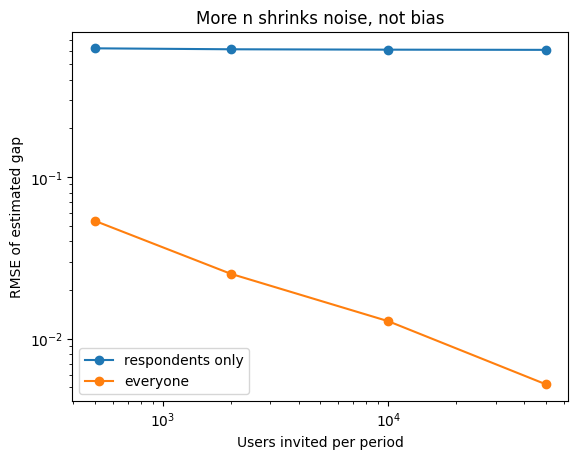

In [7]:
from statsmodels.stats.power import TTestIndPower
power = TTestIndPower()

SD = pop_sd
d = 0.10 / SD
n_needed = power.solve_power(effect_size=d, alpha=0.05, power=0.80)
print(f'SD = {SD:.3f}, d = {d:.3f}')
print(f'n per group for 80% power: {np.ceil(n_needed):.0f}')

for n in [150, 770, len(obs_after)]:
    mde = power.solve_power(nobs1=n, alpha=0.05, power=0.80)
    print(f'n = {n}: detectable effect = {mde * SD:.3f} points (d = {mde:.3f})')

# does more n help? simulate the gap at different sizes
results = []
for n in [500, 2_000, 10_000, 50_000]:
    resp_est, full_est = [], []
    for _ in range(200):
        pb, pa = simulate_population(BASE_BEFORE, n=n), simulate_population(BASE_AFTER, n=n)
        rb, ra = respond(pb, A_BEFORE, B_BEFORE), respond(pa, A_AFTER, B_AFTER)
        resp_est.append(pa.loc[ra, 'score'].mean() - pb.loc[rb, 'score'].mean())
        full_est.append(pa['score'].mean() - pb['score'].mean())
    for kind, est in [('respondents only', np.array(resp_est)), ('everyone', np.array(full_est))]:
        results.append({'n invited': n, 'estimator': kind, 'mean est': est.mean(),
                        'bias': est.mean() - 0.10, 'SD': est.std(ddof=1),
                        'RMSE': np.sqrt(((est - 0.10) ** 2).mean())})
sim = pd.DataFrame(results)
print(sim)

for kind in ['respondents only', 'everyone']:
    d_ = sim[sim.estimator == kind]
    plt.plot(d_['n invited'], d_['RMSE'], 'o-', label=kind)
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Users invited per period'); plt.ylabel('RMSE of estimated gap')
plt.title('More n shrinks noise, not bias')
plt.legend(); plt.show()

The score SD is 0.887, so a 0.10 improvement is d = 0.113. To get 80% power at α = 0.05, we'd need about 1,236 respondents per period. At like a 15% response rate that's around 8,100 invites per period.

Detectable effect (80% power) at realistic sample sizes:
- 150 respondents (1,000 invites): 0.29 points
- 770 respondents (5,000 invites): 0.13 points
- 7,597 respondents (size of the post-redesign survey): 0.04 points

So a normal follow-up of 1,000 invites basically couldn't even detect the real 0.10 improvement. But this power calc assumes respondents are a random sample, so it's really only accounting for noise.

Would a bigger sample help? Probably not. In the simulation (200 reps per size), the respondents-only estimate pretty much stays around 0.71 with bias of about +0.61 at every size. Going from 500 to 50,000 invites cuts the SD from 0.115 to 0.011, but RMSE barely moves (0.62 to 0.61) because the bias doesn't really shrink. If everyone invited actually answered, RMSE would drop from 0.053 to 0.005 and the estimate would be centered on the truth.

So more data basically just makes the wrong answer more precise. What would actually help is changing who answers, like surveying a random sample with reminders, or adjusting for who responds, like weighting on engagement and support tickets (Phase 4).

## Phase 4: AI Expansion — The Co-Pilot Era (15 pts)

**Status: AI usage AUTHORISED and REQUIRED.** You have built the simulation, the bootstrap and the power analysis by hand. Now use the **P.R.I.M.E. framework** to go further than you could in the time.

### Task 4.1: The weighting attempt (10 pts)

In [8]:
import statsmodels.api as sm

def ipw_mean(pop, resp):
    # model P(respond) using only what we can see for every user: engagement and support tickets
    X = sm.add_constant(pop[['engagement_z', 'had_support_ticket']])
    model = sm.Logit(resp.astype(int), X).fit(disp=0)
    p_hat = model.predict(X)[resp]
    w = 1 / p_hat
    y = pop.loc[resp, 'score']
    return np.average(y, weights=w), w

w_before_mean, w_b = ipw_mean(pop_before, resp_before)
w_after_mean, w_a = ipw_mean(pop_after, resp_after)

# oracle: weights using the TRUE response probabilities, which need s (we can never see this in real life)
def oracle_mean(pop, resp, a, b):
    p = expit(a + b * (pop['s'] - 3.3) + 0.30 * pop['engagement_z'] - 0.25 * pop['had_support_ticket'])
    return np.average(pop.loc[resp, 'score'], weights=1 / p[resp])

o_before = oracle_mean(pop_before, resp_before, A_BEFORE, B_BEFORE)
o_after = oracle_mean(pop_after, resp_after, A_AFTER, B_AFTER)

results = pd.DataFrame({
    'before': [TRUE_SCORE_BEFORE, obs_before.mean(), w_before_mean, o_before],
    'after': [TRUE_SCORE_AFTER, obs_after.mean(), w_after_mean, o_after],
}, index=['truth', 'raw survey', 'weighted (engagement + tickets)', 'oracle weights (needs s)'])
results['gap'] = results['after'] - results['before']
print(results.round(3))

raw_bias = obs_after.mean() - obs_before.mean() - (TRUE_SCORE_AFTER - TRUE_SCORE_BEFORE)
w_bias = results.loc['weighted (engagement + tickets)', 'gap'] - (TRUE_SCORE_AFTER - TRUE_SCORE_BEFORE)
print(f'\nBias in the gap: raw {raw_bias:.3f}, weighted {w_bias:.3f} '
      f'({1 - w_bias / raw_bias:.0%} of the bias removed)')
print(f'Max weight before: {w_b.max():.1f}, after: {w_a.max():.1f}')

                                 before  after    gap
truth                             3.290  3.386  0.096
raw survey                        3.600  4.304  0.704
weighted (engagement + tickets)   3.464  4.143  0.679
oracle weights (needs s)          3.279  3.462  0.183

Bias in the gap: raw 0.608, weighted 0.583 (4% of the bias removed)
Max weight before: 8.1, after: 44.1


**Did the weighting work? No.**

Truth: 3.290 before, 3.386 after (gap 0.096). Raw survey: 3.600 and 4.304 (gap 0.704). Weighted on engagement + tickets: 3.464 and 4.143 (gap 0.679).

Weighting removed only about 4% of the bias. This is expected: weighting assumes that once you know engagement and tickets, whether someone answers has nothing to do with their satisfaction. My response mechanism breaks that, because satisfaction itself drives response (b = 2.00 after), so the weights can't see it. Even the oracle weights give 0.183, not 0.096, because the largest weight is 44 and a few respondents dominate.

### Task 4.2: The slide (5 pts)

**Onboarding redesign: what the survey can and can't tell us**

- **Supported:** people who answered after the redesign rated it higher: 4.30 vs 3.60, a gap of **+0.70 points (95% CI 0.68 to 0.73)**.
- **Not supported:** that users got 0.70 points happier. Response fell from 27% to 15%, and mostly happy users answered. In a simulation matching our survey, a true +0.10 shows up as +0.70.
- Adjusting for engagement and tickets barely changes it (0.70 → 0.68).
- **Fix:** survey a random sample of about 1,250 users per period and follow up with non-responders until most answer.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Model and date:** Claude Opus 5.5, October 26, 2026

**Order note:** I ran my revised prompt first, then the prompt from the brief. Both are pasted below unedited.

---

**Prompt from the brief:**
[Prep] Act as a survey statistician who works on non-response
adjustment for product research.

[Request] I have a simulated user population with satisfaction scores
and two covariates, engagement_minutes and had_support_ticket, plus a
non-response mechanism where the probability of responding increases
with satisfaction. Write Python that implements inverse-probability
weighting to correct the observed survey mean, using a logistic model
of response on the covariates.

[Iterate] numpy, pandas, scikit-learn or statsmodels. Reuse my
variable names. Return the weighted estimate and its bootstrap
interval.

[Mechanism Check] Explain precisely which assumption makes this
correction valid, and what happens to it when response depends on
satisfaction ITSELF rather than only on the covariates.

[Evaluate] Given my mechanism, will this correction recover the true
mean? Answer yes or no and justify it.

**Reply:**
Here's an inverse-probability weighting estimator with a bootstrap interval, then the assumption it relies on and whether it works for your mechanism.

**Code**

This assumes a DataFrame `pop` with one row per user: `engagement_minutes`, `had_support_ticket`, `responded` (True/False), and `score` (observed only for respondents).

```python
import numpy as np
import pandas as pd
import statsmodels.api as sm

def ipw_mean(pop):
    # Response model on covariates observed for everyone
    X = sm.add_constant(pop[['engagement_minutes', 'had_support_ticket']])
    model = sm.Logit(pop['responded'].astype(int), X).fit(disp=0)
    p_hat = model.predict(X)

    # Weight each respondent by 1 / P(respond)
    resp = pop['responded'].to_numpy()
    w = 1 / p_hat[resp]
    y = pop.loc[resp, 'score']
    return np.average(y, weights=w)

def ipw_bootstrap(pop, B=500, seed=0):
    rng = np.random.default_rng(seed)
    n = len(pop)
    est = np.empty(B)
    for b in range(B):
        # Resample ALL users (respondents and non-respondents) and refit the model each time
        sample = pop.iloc[rng.integers(0, n, n)].reset_index(drop=True)
        est[b] = ipw_mean(sample)
    return ipw_mean(pop), np.percentile(est, [2.5, 97.5])

estimate, (lo, hi) = ipw_bootstrap(pop)
print(f'Raw respondent mean: {pop.loc[pop.responded, "score"].mean():.3f}')
print(f'IPW mean: {estimate:.3f}, 95% bootstrap CI [{lo:.3f}, {hi:.3f}]')
```

The bootstrap resamples the whole population and refits the logistic model in every replicate. That way the interval includes the uncertainty in the estimated weights. Resampling only respondents with fixed weights would make the interval too narrow.

**Mechanism check**

The correction is valid under **missing at random (MAR) given the covariates**. Once you condition on `engagement_minutes` and `had_support_ticket`, whether a user responds has to be independent of their satisfaction. Every respondent's response probability must also be modeled correctly and be above zero.

If response depends on satisfaction **itself**, the data are **missing not at random (MNAR)**. Two users with identical engagement and ticket history then respond at different rates depending on how satisfied they are. The logistic model can't capture that, because satisfaction isn't in it. The weights fix only the part of the selection that runs through the covariates. Within every covariate group, respondents are still happier than non-respondents, so the weighted mean stays biased upward.

**Evaluate**

**No.** Your response probability depends directly on satisfaction, so MAR fails and IPW on these two covariates won't recover the true mean. It moves the estimate toward the truth only as far as satisfaction is explained by engagement and tickets. If those covariates explain only a modest part of satisfaction, the correction will be small and most of the bias remains. Getting the true mean requires either a design fix, like a random sample with intensive follow-up of non-responders, or an outcome observed for everyone.

---

**My revised prompt:**
I'm a data analyst. Our post-redesign satisfaction survey went from 3.6 to 4.3, but the response rate dropped from 27% to 15% and response probability depends on satisfaction itself. I can observe engagement_z and had_support_ticket for every user. In Python, how would I do inverse probability weighting with a logistic regression on those two variables, and can weighting remove the bias when response depends on the outcome? Give me the code and a 3-sentence explanation I could put on a slide for a non-technical PM.

**Reply:**
Here's how to do it, then the answer to whether it works.

**Code**

Assume a DataFrame `users` with one row per user in a period: `engagement_z`, `had_support_ticket`, `responded` (True/False), and `score` (NaN for non-respondents).

```python
import numpy as np
import pandas as pd
import statsmodels.api as sm

def ipw_mean(users):
    # 1. Model the probability of responding from variables observed for everyone
    X = sm.add_constant(users[['engagement_z', 'had_support_ticket']])
    model = sm.Logit(users['responded'].astype(int), X).fit(disp=0)
    users = users.assign(p_hat=model.predict(X))

    # 2. Weight each respondent by 1 / predicted response probability
    resp = users[users['responded']]
    w = 1 / resp['p_hat']

    # 3. Weighted mean, plus diagnostics
    weighted = np.average(resp['score'], weights=w)
    ess = w.sum() ** 2 / (w ** 2).sum()          # effective sample size
    return {'raw mean': resp['score'].mean(),
            'weighted mean': weighted,
            'max weight': w.max(),
            'effective n': ess,
            'respondents': len(resp)}

before = ipw_mean(users_before)
after = ipw_mean(users_after)
print(pd.DataFrame({'before': before, 'after': after}).round(3))
print('Weighted gap:', round(after['weighted mean'] - before['weighted mean'], 3))
```

It's also worth checking balance. After weighting, the respondents' mean `engagement_z` and ticket rate should match those of all users.

**Can weighting remove the bias? No, not when response depends on satisfaction itself.**

Inverse probability weighting assumes that once you account for engagement and tickets, whether someone answers is unrelated to their satisfaction. You've said response depends on satisfaction directly, so that assumption fails and the data are missing not at random. The model can only correct the part of the selection that flows through engagement and tickets. Among two users with identical engagement and ticket history, the happier one is still more likely to answer, and nothing in the weights can see that. Expect the weighted gap to move only a little from the raw 0.7. How much depends on how strongly satisfaction relates to engagement and tickets, and here it's probably only a small fraction of the bias. Treat the weighted number as a sensitivity check, not a correction. The real fixes are a random sample with follow-up of non-responders, or an outcome you observe for every user.

**Slide explanation (3 sentences)**

> The jump from 3.6 to 4.3 mostly reflects who answered the survey: after the redesign, far fewer people responded, and the ones who did were the happiest users. Adjusting for what we know about users, like engagement and support tickets, barely changes the result, because the main reason people skip the survey is that they're less satisfied, which we can't see. To know whether the redesign actually worked, we need to survey a random sample of users and follow up with those who don't respond.

---

**My revision (what my prompt fixes compared with the brief's prompt):**
- The brief's prompt says to "correct the observed survey mean", but my question is about the before/after **gap**. My prompt asks about the gap, and its reply computes both periods.
- The brief's prompt names `engagement_minutes`; my data uses `engagement_z`. My prompt names the variables I actually have.
- I added my real numbers 3.6 to 4.3, response rate 27% to 15% so the answer was about my survey.
- I asked for a short slide explanation for a non-technical PM so the output was usable.

**My check:** Run against my known truth (cell above), the weighted gap is 0.679 versus a true gap of 0.096 (raw 0.704). The correction failed, as both replies predicted.

**My critique:** The brief's prompt says "reuse my variable names" but never gives them, so the reply invented a `pop` DataFrame with a `responded` column and corrected one mean instead of the gap. My prompt's reply computes the gap but returns no bootstrap interval, even though the task asks for one.

**In my own words:** The logistic regression predicts each user's chance of answering from engagement_z and had_support_ticket, using all users. `w = 1 / p_hat` makes a respondent with a 5% chance of answering count as 20 users, so groups that rarely answer get their real share back. `np.average(y, weights=w)` gives the weighted mean score.

**Would I use AI again?** Yes for writing the code, because I could check it against the true means I simulated. I stopped once the result matched what I could verify: the correction fails, and I understand why.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_3916_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.